In [1]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error
import copy

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Acoustic_spectral_analysis')
import Acoustic_additionnal_analysis_func
importlib.reload(Acoustic_additionnal_analysis_func)
from Acoustic_additionnal_analysis_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Acoustic_spectral_analysis')
import Acoustic_additionnal_analysis_plotting
importlib.reload(Acoustic_additionnal_analysis_plotting)
from Acoustic_additionnal_analysis_plotting import *

fontsize = 25

### Get fully treated data

In [2]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR2.3\zone3\NDd\2025-11'
dir_name = r'2025-11-20_PaP_Pp10uW_ldap410nm_ldas660nm'
dir_name += '_treated'
filename= 'Trace'



filename_acoustic = filename + '_acoustic_fitted'

Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename_acoustic)

## Spectral Study

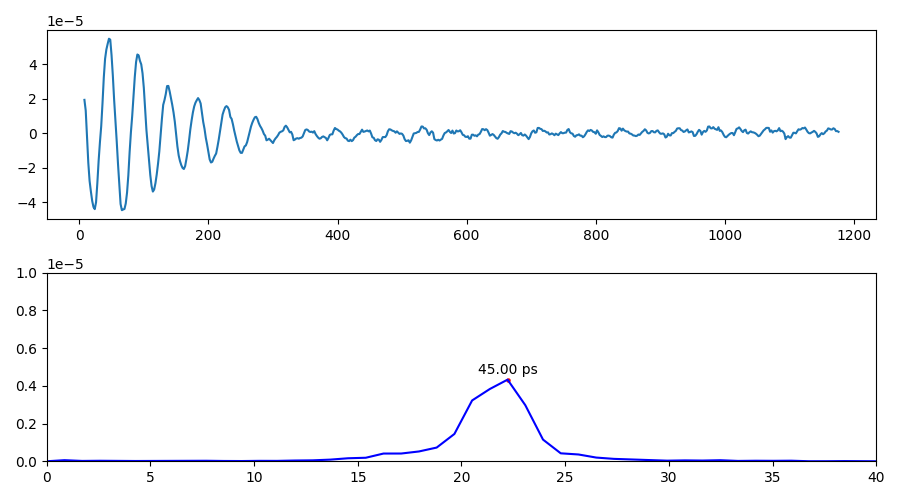

In [3]:
ylim=100e-7
xlim=(0, 40)


fig_raw_tf, ax_raw_tf = plt.subplots(nrows=2, figsize = (9, 5))

ax_raw_tf[0].plot(Trace.delay, Trace.DTT_acoustic)
plot_tf_module(Trace.tf_acoustic, ax_raw_tf[1], color='blue')


ax_raw_tf[1].set_ylim(0,ylim)
ax_raw_tf[1].set_xlim(xlim)

plt.tight_layout()
plt.show()

Make a padded acoustic signal

In [4]:
Transform_signals = {}

In [5]:
Transform_signals['Padded_signal'] = {}
Transform_signals['Padded_signal']['DTT'], Transform_signals['Padded_signal']['delay'] = padd_signal(2000, Trace.DTT_acoustic, Trace.delay)
Transform_signals['Padded_signal']['tf'] = study_tf(Transform_signals['Padded_signal']['DTT'], Transform_signals['Padded_signal']['delay'], Trace.dt, height=1e-5, threshold=1e-5 )

Make a cropped signal at the end

In [6]:
height = 5e-8
threshold = 1e-7
t_begin = 400
t_stop = 1200


idx_begin = np.searchsorted(Trace.delay, t_begin)
idx_end = np.searchsorted(Trace.delay, t_stop)
Transform_signals['Cropped_signal'] = {}
Transform_signals['Cropped_signal']['DTT'], Transform_signals['Cropped_signal']['delay'] = Trace.DTT_acoustic[idx_begin:idx_end], Trace.delay[idx_begin:idx_end]
height = 5e-8
threshold = 1e-7
Transform_signals['Cropped_signal']['tf'] = study_tf(Transform_signals['Cropped_signal']['DTT'], Transform_signals['Cropped_signal']['delay'], Trace.dt, height=height, threshold = threshold )

In [7]:
height = 5e-8
threshold = 1e-7
t_begin = 500
t_stop = 1200

Transform_signals['Signal_without_modes'] = {}

Transform_signals['Signal_without_modes']['DTT'], Transform_signals['Signal_without_modes']['delay'] = remove_acoustic_modes(Trace,1), Trace.delay
height = 5e-8
threshold = 1e-7
Transform_signals['Signal_without_modes']['tf'] = study_tf(Transform_signals['Signal_without_modes']['DTT'], Transform_signals['Signal_without_modes']['delay'], Trace.dt, height=height, threshold = threshold )

Plot raw and padded signals

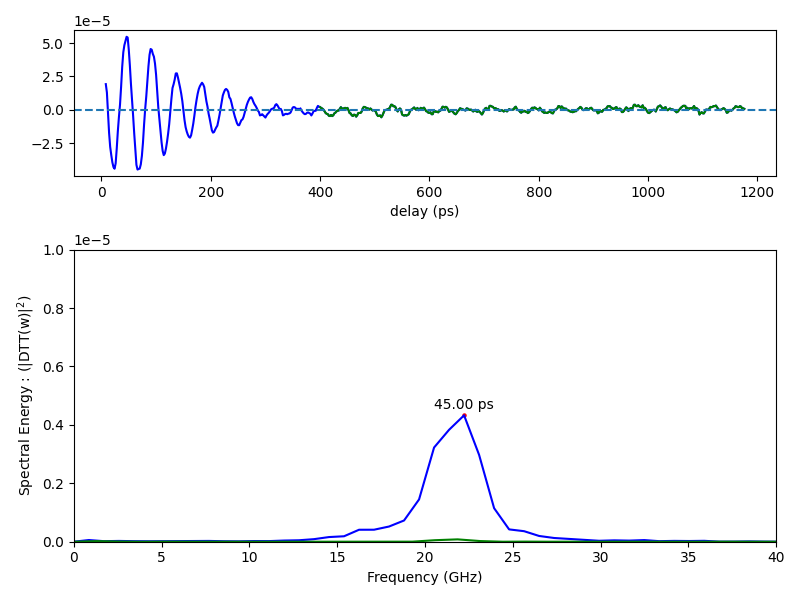

In [8]:
key_to_plot = 'Cropped_signal'

#key_to_plot = 'Padded_signal'
ylim=100e-7
xlim=(0, 40)


f, (a0, a1) = plt.subplots(2,1, figsize=(8,6),
gridspec_kw = {'height_ratios':[1, 2]})


a0.plot(Trace.delay, Trace.DTT_acoustic, color='blue')
a0.plot(Transform_signals[key_to_plot]['delay'], Transform_signals[key_to_plot]['DTT'], color='green')
a0.set_xlabel('delay (ps)')


plot_tf_module(Trace.tf_acoustic, a1, color='blue')
plot_tf_module(Transform_signals[key_to_plot]['tf'], a1, color='green')


a0.axhline(0, linestyle='--')

a1.set_ylim(0,ylim)
a1.set_xlim(xlim)
a1.set_xlabel('Frequency (GHz)')
a1.set_ylabel(r'Spectral Energy : (|DTT(w)|$^2$)')

plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
#plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


Remove 1 acoustic modes

In [9]:
#p0 = A1, tau1, T1, phi1, A2, tau2, T2, phi2, A3, tau3, T3, phi3, A4, tau4, T4, phi4
A1_0, tau1_0, T1_0, phi1_0 = 1e-5, 1000, 1/(22)*1e3, (100)*np.pi/180
A2_0, tau2_0, T2_0, phi2_0 = 1e-5, 100,1/(20.5)*1e3, (-146)*np.pi/180
A3_0, tau3_0, T3_0, phi3_0 = 0.1e-5, 100, 31, -100*np.pi/180
A4_0, tau4_0, T4_0, phi4_0 = 0.5e-5, 200, 30, 0.5


p0 = A1_0, tau1_0, T1_0, phi1_0, A2_0, tau2_0, T2_0, phi2_0, A3_0, tau3_0, T3_0, phi3_0, A4_0, tau4_0, T4_0, phi4_0

Bounds_low = [ 0, 0, 0, -np.pi, 0, 0, 0, -np.pi, 0, 0, 0, -np.pi, 0, 0, 0, -np.pi]
Bounds_high= [np.inf,np.inf,np.inf,np.pi,np.inf, np.inf, np.inf, np.pi,np.inf,np.inf,np.inf,np.pi,np.inf, np.inf, np.inf, np.pi]


(res1, res2, res3, res4) = fit_signal_osc(Transform_signals['Signal_without_modes']['DTT'], Transform_signals['Signal_without_modes']['delay'], p0, Bounds_low, Bounds_high)

popt1, incert_1, err_1 = res1
popt2, incert_2, err_2 = res2
popt3, incert_3, err_3 = res3
popt4, incert_4, err_4 = res4

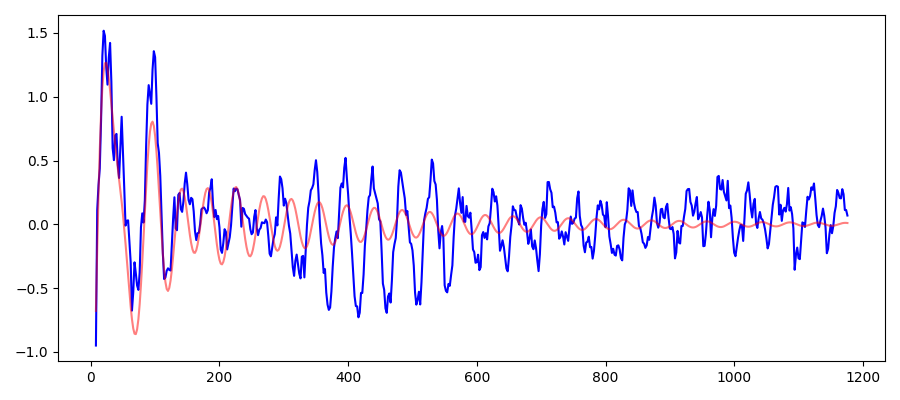

In [10]:
tmax=1200

fig, ax = plt.subplots(figsize=(9,4))

ax.plot(Transform_signals['Signal_without_modes']['delay'], Transform_signals['Signal_without_modes']['DTT']*1e5, label='Raw signal', c='blue')
ax.plot(Transform_signals['Signal_without_modes']['delay'], Osc2(Transform_signals['Signal_without_modes']['delay'],*popt2)*1e5, 'r-', alpha=0.5,label='fit')

plt.tight_layout()
plt.show()

Lorentzian fit

In [11]:
f_low = 23
f_high = 27

res_fit_tf = Lorentz_fit_tf(Trace.tf_acoustic, f_low, f_high)

In [12]:
print(res_fit_tf['Q'], res_fit_tf['Q_err'])
#print(res_fit_tf)

13.346352403228545 0.9754731382366868


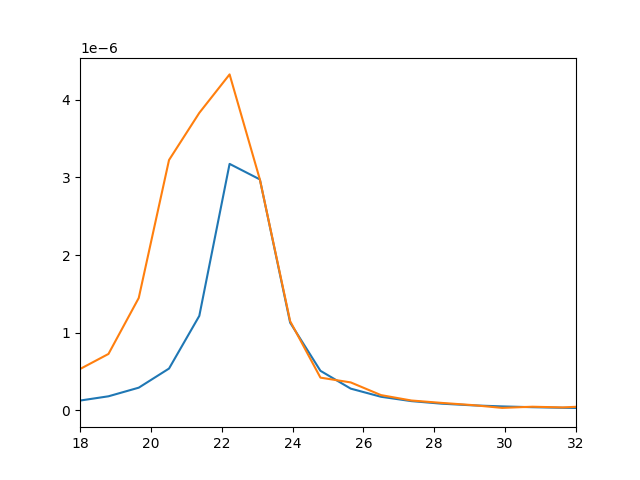

In [13]:
fig = plt.figure()

plt.plot(Trace.tf_acoustic['freq'], Lorentz_no_offset(Trace.tf_acoustic['freq'], *res_fit_tf['coeffs']))
plt.plot(Trace.tf_acoustic['freq'], Trace.tf_acoustic['amp']**2)
plt.xlim((f_low-5, f_high+5))
plt.show()

### Save data